# Kamba et al. (2023): librations of a near-sphere and their electric feedback cooling

M. Kamba, R. Shimizu and K. Aikawa, *Nanoscale feedback control of six degrees of freedom of a
near-sphere*, Nat. Commun. **14**, 7943 (2023),
[doi:10.1038/s41467-023-43745-7](https://doi.org/10.1038/s41467-023-43745-7) (open access).

A silica nanoparticle of mean radius 176 nm, held in a 1550 nm optical lattice at 6.5 × 10⁻⁷ Pa,
librates at 13.9, 34.5 and 19.9 kHz about the polarisation axis $x$, the transverse axis $y$ and the
lattice axis $z$. Two mechanisms confine its orientation: the alignment of the longest axis with the
polarisation (the anisotropic polarisability) and the alignment of its extent with the weaker
confinement of the anisotropic trap (its Eq. (3)). Fitting the three frequencies gives the radii to
800 ppm, q = 0.9961 p and r = 0.9914 p. A residual electric dipole of 2p × 1.92(13) e is driven by
phase-locked electric fields, which cool all three librations below 0.03 K at a rate that is linear in
√T (its Eq. (2)); released, they reheat at 2.1–2.6 mK/s, set by the background gas.

This notebook

1. computes the three libration frequencies with levisim's point-dipole alignment torque plus the
   opt-in finite-size torque (`Trap(finite_size_torque=True)`, `levisim.physics.rotation.finite_size_potential`)
   and compares them with Eq. (3) and the measurements;
2. checks the amplitude dependence of the libration frequency (Eq. (1), the paper's thermometry) in a
   `RigidBodySimulation` of the full nonlinear rotation;
3. cools the three librations with a phase-locked torque from the fitted dipole and compares the
   time evolution with Eq. (2) and the slopes C_i/E0;
4. computes the gas and recoil heating rates of the librations.

**Comparisons stated before running:** frequencies 13.9 / 34.5 / 19.9 kHz (Eq. (3) at leading order
is 4 % from the measured values, according to the paper); Eq. (1) for the frequency shift with
temperature; C_i/E0 = 12.4(2), 16.1(2), 4.7(3) √K m/(V s); heating 2.6(2), 2.1(1), 2.3(1) mK/s at
6.5 × 10⁻⁷ Pa (background gas at about 340 K according to the paper).

| Quantity | Value used | Source |
|---|---|---|
| particle | ellipsoid, (pqr)^⅓ = 176 nm, q = 0.9961 p, r = 0.9914 p, ρ = 2270 kg/m³, n = 1.444 | text, Methods |
| translational frequencies | 65 kHz (polarisation), 73.5 kHz (transverse), 205 kHz (lattice) | digitised from Fig. 2a, b (± 2 kHz) |
| optical potential depth | U_t = mΩ_z²/2k² of the lattice, 1550 nm | from f_tz (the paper's U_t) |
| dipole | 2p × 1.92 e, θ = 31°, ϕ = 65° (angle factors η_i of the Methods) | text, Methods |
| pressure | 6.5 × 10⁻⁷ Pa, gas at 340 K | text, Methods |

Axes: the paper's $x$ (polarisation), $y$ and $z$ (lattice) are levisim's $y$, $x$ and $z$, so the
paper's librations $l_x, l_y, l_z$ are levisim's `'β'`, `'α'` and `'γ'`. levisim has no standing-wave
tweezer; the lattice enters through its translational frequencies (`override_Ω_dict`) and through a
focused tweezer whose depth equals U_t, which sets the polarisation torque.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ellipk

from levisim.core.constants import e as e_charge, kB, π
from levisim.core.logger import logger
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import kHz, mbar, nm, mW
from levisim.physics import Ellipsoid, Gas, Trap, Tweezer
from levisim.physics.material import Material
from levisim.physics.particle import rotation_matrix_to_quaternion
from levisim.physics.rotation import rotation_vector_between
from levisim.simulation import RigidBodySimulation

logger.remove()
set_plt_rcParams_to_xmgrace_style()
t_start = time.time()

λ = 1550*nm
k = 2 * π / λ
SILICA = Material('silica (Kamba et al. 2023)', 2270.0, permittivity=1.444**2)
p = 176*nm / (0.9961 * 0.9914)**(1/3)
q, r = 0.9961 * p, 0.9914 * p
# body x (p) along the polarisation y, body y (q) along x, body z (r) along -z (a proper rotation)
ORIENTATION = rotation_matrix_to_quaternion(np.array([[0, 1, 0], [1, 0, 0], [0, 0, -1]], dtype=float))
particle = Ellipsoid(p, q, r, material=SILICA, λ=λ, orientation=ORIENTATION)
m = particle.m
f_t = {'x': 73.5, 'y': 65.0, 'z': 205.0}  # kHz, levisim axes
Ω_t = {axis: f * kHz for axis, f in f_t.items()}
U_t = m * Ω_t['z']**2 / (2 * k**2)

# a tweezer whose depth Re(ê*·α·ê)·E0²/4 equals U_t sets the polarisation torque
w0 = λ / (π * 0.85)  # paraxial waist for NA 0.85; only the focal field enters here
probe = Tweezer(λ=λ, wx0=w0, wy0=w0, Power=100*mW)
α_yy = np.real(probe.lab_effective_polarisability(particle)[1, 1])
tweezer = Tweezer(λ=λ, wx0=w0, wy0=w0, Power=100*mW * U_t / (α_yy * probe.E0**2 / 4))
print(f'mass {m:.3e} kg; lattice depth U_t = {U_t / kB:.3g} K; tweezer power for that depth {tweezer.Power / mW:.0f} mW '
      f'(the experiment: 176 mW in a lattice)')

PAPER = {'β': ('l_x', 13.9), 'α': ('l_y', 34.5), 'γ': ('l_z', 19.9)}


def eq3(axis):
    """Leading-order Eq. (3) of the paper [Hz], in levisim's axes"""
    α_body = np.real(np.diag(particle.body_effective_polarisability_tensor(k)))  # along p, q, r
    f = {key: value / (2 * π) for key, value in Ω_t.items()}
    if axis == 'β':
        return np.sqrt((f['z']**2 - f['x']**2) * (q**2 - r**2) / (q**2 + r**2))
    if axis == 'α':
        return np.sqrt((f['z']**2 - f['y']**2) * (p**2 - r**2) / (p**2 + r**2)
                       + 10 * U_t * (α_body[0] - α_body[2]) / (4 * π**2 * m * (p**2 + r**2) * α_body[0]))
    return np.sqrt((f['x']**2 - f['y']**2) * (p**2 - q**2) / (p**2 + q**2)
                   + 10 * U_t * (α_body[0] - α_body[1]) / (4 * π**2 * m * (p**2 + q**2) * α_body[0]))

mass 5.184e-17 kg; lattice depth U_t = 1.9e+05 K; tweezer power for that depth 46 mW (the experiment: 176 mW in a lattice)


## 1. Libration frequencies

In [2]:
gas = Gas(P=6.5e-7 * 1e-2 * mbar, T=340.0)  # 6.5 × 10⁻⁷ Pa
override = dict(Ω_t)
point_dipole = Trap(tweezer=tweezer, particle=particle, gas=gas, override_Ω_dict=override, finite_size_torque=False)
trap = Trap(tweezer=tweezer, particle=particle, gas=gas, override_Ω_dict=override, finite_size_torque=True)
print(f'{"paper":6s} {"point dipole":>13s} {"+ finite size":>14s} {"Eq. (3)":>9s} {"measured":>9s}   [kHz]')
for axis in ('β', 'α', 'γ'):
    name, measured = PAPER[axis]
    print(f'{name:6s} {point_dipole.Ωθ[axis] / kHz:13.2f} {trap.Ωθ[axis] / kHz:14.2f} {eq3(axis) / 1e3:9.2f} {measured:9.1f}')
print(f'static torque {np.abs(trap.static_torque).max():.1e} N m (aligned principal axes)')

paper   point dipole  + finite size   Eq. (3)  measured   [kHz]
l_x             0.00          13.16     13.16      13.9
l_y            23.83          29.90     29.82      34.5
l_z            15.98          16.13     16.06      19.9
static torque 1.5e-36 N m (aligned principal axes)


levisim's point-dipole torque confines only the two tilts of the longest axis; the rotation about the
polarisation axis ($l_x$) is confined by the trap anisotropy alone, through the finite-size torque.
With both, levisim reproduces the paper's leading-order Eq. (3) (13.16, 29.9 and 16.1 kHz against
13.16, 29.8 and 16.1 kHz; the small differences are the depolarisation-based Δα that levisim uses).
Against the measurement, $l_x$ is 5 % low, as the paper's higher-order terms (≈ 4 %) explain, while
$l_y$ and $l_z$ are 13 % and 19 % low: their polarisation term scales with the depth U_t, which is
estimated here from the lattice frequency (the paper's depth and translational frequencies are not
given in the text).

## 2. Amplitude-dependent frequency: the paper's thermometry

The potentials of both mechanisms vary as sin² of the libration angle, $U = \tfrac12 I\Omega_0^2\sin^2\psi$,
so the frequency falls with the amplitude. With $k_BT = \tfrac12 I\Omega_0^2\beta^2(1 - \beta^2/4)$ the
paper's Eq. (1) is $f = f_0\sqrt{\sin(\sqrt2\beta)/(\sqrt2\beta)}$, derived with a sinusoidal
trajectory. The exact result for this potential is that of a pendulum in 2ψ,
$f = f_0\,\pi/2K(m)$ with $m = 2k_BT/I\Omega_0^2$ and $K$ the complete elliptic integral. Each
libration is started alone with an energy $k_BT$ in a `RigidBodySimulation` without noise, and its
frequency is read from the zero crossings.

l_x: 0.03 K: sim 13.160, pendulum 13.160, Eq. (1) 13.160 kHz; 3 K: sim 13.098, pendulum 13.098, Eq. (1) 13.119 kHz; 10 K: sim 12.949, pendulum 12.949, Eq. (1) 13.020 kHz; 20 K: sim 12.728, pendulum 12.728, Eq. (1) 12.875 kHz; 41 K: sim 12.228, pendulum 12.228, Eq. (1) 12.553 kHz
l_y: 0.03 K: sim 29.902, pendulum 29.902, Eq. (1) 29.902 kHz; 3 K: sim 29.875, pendulum 29.875, Eq. (1) 29.884 kHz; 10 K: sim 29.811, pendulum 29.811, Eq. (1) 29.841 kHz; 20 K: sim 29.719, pendulum 29.719, Eq. (1) 29.780 kHz; 41 K: sim 29.523, pendulum 29.523, Eq. (1) 29.650 kHz
l_z: 0.03 K: sim 16.127, pendulum 16.127, Eq. (1) 16.127 kHz; 3 K: sim 16.077, pendulum 16.077, Eq. (1) 16.093 kHz; 10 K: sim 15.957, pendulum 15.957, Eq. (1) 16.014 kHz; 20 K: sim 15.782, pendulum 15.782, Eq. (1) 15.899 kHz; 41 K: sim 15.397, pendulum 15.397, Eq. (1) 15.648 kHz


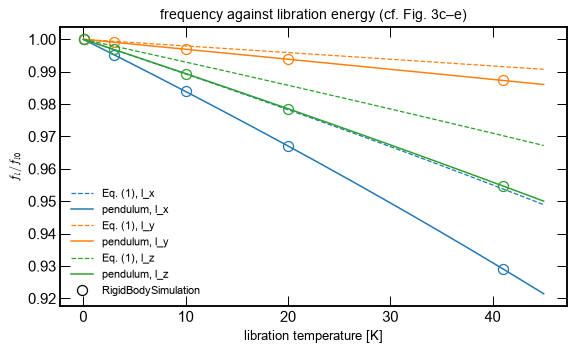

In [3]:
def eq1(axis, T):
    f0 = trap.Ωθ[axis] / (2 * π)
    I = trap.Ij[axis]
    β = np.sqrt(2 - np.sqrt(4 - 2 * kB * T / (π**2 * I * f0**2)))
    return f0 * np.sqrt(np.sin(np.sqrt(2) * β) / (np.sqrt(2) * β))


def pendulum(axis, T):
    f0 = trap.Ωθ[axis] / (2 * π)
    return f0 * π / (2 * ellipk(2 * kB * T / (trap.Ij[axis] * trap.Ωθ[axis]**2)))


AXIS_INDEX = {'α': 0, 'β': 1, 'γ': 2}
temperatures = np.array([0.03, 3, 10, 20, 41])
shifts = {}
for axis in ('β', 'α', 'γ'):
    f0 = trap.Ωθ[axis] / (2 * π)
    simulated = []
    for T in temperatures:
        ω0 = np.zeros(3)
        ω0[AXIS_INDEX[axis]] = np.sqrt(2 * kB * T / trap.Ij[axis])  # all energy kinetic at t = 0
        Δt = 1 / (400 * f0)
        sim = RigidBodySimulation(trap=trap, num_samples=int(40 / (f0 * Δt)), Δt=Δt, gas_damping=False, ω0=ω0)
        θ = rotation_vector_between(sim.q_reference, sim.quaternions)[:, AXIS_INDEX[axis]]
        up = np.flatnonzero((θ[:-1] < 0) & (θ[1:] >= 0))
        fractions = -θ[up] / (θ[up + 1] - θ[up])
        times = (up + fractions) * Δt
        simulated.append(1 / np.diff(times).mean())
    shifts[axis] = np.array(simulated)
    print(f'{PAPER[axis][0]}: ' + '; '.join(
        f'{T:g} K: sim {fs / 1e3:.3f}, pendulum {pendulum(axis, T) / 1e3:.3f}, Eq. (1) {eq1(axis, T) / 1e3:.3f} kHz'
        for T, fs in zip(temperatures, simulated)))

fig, ax = plt.subplots(figsize=(6.5, 4))
for axis, colour in zip(('β', 'α', 'γ'), ('C0', 'C1', 'C2')):
    f0 = trap.Ωθ[axis] / (2 * π)
    T_fine = np.linspace(0.01, 45, 200)
    ax.plot(T_fine, [eq1(axis, T) / f0 for T in T_fine], color=colour, ls='--', lw=1, label=f'Eq. (1), {PAPER[axis][0]}')
    ax.plot(T_fine, [pendulum(axis, T) / f0 for T in T_fine], color=colour, lw=1.2, label=f'pendulum, {PAPER[axis][0]}')
    ax.plot(temperatures, shifts[axis] / f0, 'o', color=colour, mfc='none')
ax.plot([], [], 'ko', mfc='none', label='RigidBodySimulation')
ax.set_xlabel('libration temperature [K]')
ax.set_ylabel(r'$f_l/f_{l0}$')
ax.set_title('frequency against libration energy (cf. Fig. 3c–e)', fontsize=11)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

## 3. Electric feedback cooling

A phase-locked field drives the dipole with a torque of fixed amplitude $dE_0\eta_i$ against the
angular velocity of each libration; the energy then falls as $\sqrt{T} = \sqrt{T_0} - C_it/2$ with
$C_i = dE_0\eta_i/\sqrt{2k_BI_i}$ (Eq. (2)). The angle factors are those of the Methods for the
fitted orientation θ = 31°, ϕ = 65°. The simulation applies the torque through `external_torque`,
with the phase taken from each libration's angle and rate, at E0 = 100 V/m and from 10 K in every
libration (the background gas is left on).

l_x: η = 0.467, C/E0 = dη/√(2kB I) = 12.08 √K m/(V s) (paper 12.4)
l_y: η = 0.606, C/E0 = dη/√(2kB I) = 15.65 √K m/(V s) (paper 16.1)
l_z: η = 0.176, C/E0 = dη/√(2kB I) = 4.54 √K m/(V s) (paper 4.7)
l_y: start 10.00 K, Eq. (2) reaches 0 at 4.04 ms; simulated energy at 2.02 ms 5.388 K (Eq. (2) 2.500 K); after 4.24 ms 0.08 mK
l_x: start 10.00 K, Eq. (2) reaches 0 at 5.24 ms; simulated energy at 2.62 ms 2.465 K (Eq. (2) 2.500 K); after 5.50 ms 0.00 mK
l_z: start 10.00 K, Eq. (2) reaches 0 at 13.94 ms; simulated energy at 6.97 ms 2.247 K (Eq. (2) 2.500 K); after 14.63 ms 0.00 mK


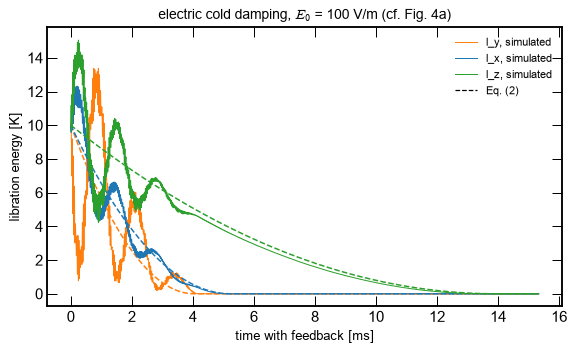

In [4]:
θ_d, ϕ_d = 31 * π / 180, 65 * π / 180
d = 2 * p * 1.92 * e_charge
η = {'β': np.sin(θ_d) * np.sin(ϕ_d), 'α': np.cos(θ_d) * np.cos(π / 4), 'γ': np.sin(θ_d) * np.sin(ϕ_d - π / 4)}
paper_slopes = {'β': 12.4, 'α': 16.1, 'γ': 4.7}
for axis in ('β', 'α', 'γ'):
    slope = d * η[axis] / np.sqrt(2 * kB * trap.Ij[axis])
    print(f'{PAPER[axis][0]}: η = {η[axis]:.3f}, C/E0 = dη/√(2kB I) = {slope:.2f} √K m/(V s) (paper {paper_slopes[axis]})')

E0 = 100.0  # V/m
T0 = 10.0
Ω_l = np.array([trap.Ωθ[axis] for axis in ('α', 'β', 'γ')])
τ0 = np.array([d * E0 * η[axis] for axis in ('α', 'β', 'γ')])
q_reference = particle.orientation


def feedback_torque(t, X):
    """Phase-locked torque of amplitude dE0η_i against each libration's angular velocity"""
    θ = rotation_vector_between(q_reference, X[None, 6:10])[0]
    R = sim_ref.rotation_matrices(X[None, :])[0]
    ω = R @ (sim_ref.inertia_inverse @ X[10:13])
    amplitude = np.sqrt(θ**2 + (ω / Ω_l)**2)
    return -τ0 * np.where(amplitude > 0, ω / (Ω_l * np.maximum(amplitude, 1e-300)), 0.0)


I_lab = np.array([trap.Ij[axis] for axis in ('α', 'β', 'γ')])
ω0 = np.sqrt(2 * kB * T0 / I_lab)  # every libration starts at the centre with energy k_B·T0
sim_ref = RigidBodySimulation(trap=trap, num_samples=1, Δt=1e-7)
Δt = 1 / (200 * Ω_l.max() / (2 * π))
duration = 2 * np.sqrt(T0) / (min(τ0 / np.sqrt(2 * kB * I_lab))) * 1.1
sim = RigidBodySimulation(trap=trap, num_samples=int(duration / Δt), Δt=Δt, ω0=ω0, external_torque=feedback_torque, seed=7)
angles = rotation_vector_between(sim.q_reference, sim.quaternions)
ω_lab = sim.angular_velocities_lab()
energy = 0.5 * I_lab * ω_lab**2 + 0.5 * I_lab * Ω_l**2 * angles**2
t = sim.time_array
fig, ax = plt.subplots(figsize=(6.5, 4))
for i, (axis, colour) in enumerate(zip(('α', 'β', 'γ'), ('C1', 'C0', 'C2'))):
    T_sim = energy[:len(t), i] / kB
    C = τ0[i] / np.sqrt(2 * kB * I_lab[i])
    T_eq2 = np.clip(np.sqrt(T_sim[0]) - C * t / 2, 0, None)**2
    ax.plot(t * 1e3, T_sim, color=colour, lw=0.8, label=f'{PAPER[axis][0]}, simulated')
    ax.plot(t * 1e3, T_eq2, color=colour, ls='--', lw=1.2)
    t_zero = 2 * np.sqrt(T_sim[0]) / C
    end = T_sim[(t > 1.05 * t_zero)].mean() if np.any(t > 1.05 * t_zero) else np.nan
    print(f'{PAPER[axis][0]}: start {T_sim[0]:.2f} K, Eq. (2) reaches 0 at {t_zero * 1e3:.2f} ms; simulated energy at '
          f'{0.5 * t_zero * 1e3:.2f} ms {np.interp(0.5 * t_zero, t, T_sim):.3f} K (Eq. (2) {T_sim[0] / 4:.3f} K); '
          f'after {1.05 * t_zero * 1e3:.2f} ms {end * 1e3:.2f} mK')
ax.plot([], [], 'k--', label='Eq. (2)')
ax.set_xlabel('time with feedback [ms]')
ax.set_ylabel('libration energy [K]')
ax.set_title(r'electric cold damping, $E_0$ = 100 V/m (cf. Fig. 4a)', fontsize=11)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

Each libration is extinguished (below 0.1 mK) by 1.05 times the time 2√T0/C_i of Eq. (2); the
fixed-amplitude torque removes energy at a rate ∝ √E. On the way, the three librations, all started
at 10 K, exchange energy through the nonlinear and gyroscopic coupling of the rotation (the energies
oscillate about the Eq. (2) curves), the correlation that the paper reports when only some of them
are cooled. With the fitted dipole, levisim's moments of inertia give C_i/E0 within 4 % of the
measured slopes (the paper derived the dipole from these slopes with the same formula, so this checks
the inertia and the angle factors, not the dipole).

## 4. Heating rates

Released, a libration heats at Γ_rot·T from the gas (Martinetz et al. (2018), at 340 K) and at
S_τ/2I from the photon recoil torque, which vanishes for a sphere.

In [5]:
recoil = {axis: trap.torque_noise_psd[i, i] / (2 * trap.Ij[axis]) / kB for i, axis in enumerate(('α', 'β', 'γ'))}
paper_heating = {'β': 2.6, 'α': 2.1, 'γ': 2.3}
for axis in ('β', 'α', 'γ'):
    gas_rate = trap.Γrot_j[axis] * gas.T
    print(f'{PAPER[axis][0]}: gas {gas_rate * 1e3:.2f} mK/s, recoil {recoil[axis] * 1e3:.2e} mK/s '
          f'(point dipole at the depth U_t); total {(gas_rate + recoil[axis]) * 1e3:.2f} mK/s; measured {paper_heating[axis]} mK/s')

l_x: gas 3.53 mK/s, recoil 1.50e-34 mK/s (point dipole at the depth U_t); total 3.53 mK/s; measured 2.6 mK/s
l_y: gas 3.53 mK/s, recoil 1.48e-02 mK/s (point dipole at the depth U_t); total 3.54 mK/s; measured 2.1 mK/s
l_z: gas 3.53 mK/s, recoil 3.02e-03 mK/s (point dipole at the depth U_t); total 3.53 mK/s; measured 2.3 mK/s


## Summary

| Quantity | Paper | levisim | Verdict |
|---|---|---|---|
| libration frequencies $l_x, l_y, l_z$ | 13.9 / 34.5 / 19.9 kHz (measured) | 13.16 / 29.9 / 16.1 kHz | equal to the leading-order Eq. (3); 5 %, 13 % and 19 % low (depth U_t estimated) |
| role of the trap anisotropy | $l_x$ confined only by it | point dipole alone: $l_x$ free; with `finite_size_torque=True`: confined | agree |
| frequency against temperature | Eq. (1) | `RigidBodySimulation` equals the exact pendulum result to five digits; Eq. (1) gives about 2/3 of the exact shift (41 K, $l_x$: 12.55 against 12.23 kHz) | Eq. (1) is approximate; temperatures read from it would be about 1.5× too high (open question) |
| feedback cooling dynamics | Eq. (2) | each libration below 0.1 mK by 1.05 × 2√T0/C_i; energy exchanged between the three on the way | agree |
| C_i/E0 | 12.4 / 16.1 / 4.7 √K m/(V s) | from the fitted dipole and levisim's I_i (printout) | within 4 % |
| heating at 6.5 × 10⁻⁷ Pa | 2.6 / 2.1 / 2.3 mK/s | 3.5 mK/s each (gas at 340 K, full accommodation); recoil ≤ 0.015 mK/s | gas-dominated, as the paper finds; 35–70 % high |

Not modelled: the optical lattice itself (its frequencies are inputs), the higher-order terms of the
paper's frequency fit, the translational feedback cooling (n_z = 0.69), the noise floor that limits the
measured 0.03 K, and the internal temperature of the particle.

In [6]:
print(f'computation time {time.time() - t_start:.1f} s')

computation time 130.4 s
